In [ ]:
!pip install -q kagglehub opencv-python-headless

In [ ]:
import os
import cv2
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from sklearn.model_selection import train_test_split


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("using device:", device)

using device: cuda


In [ ]:
path = kagglehub.dataset_download("mdtasnimulhassankhan/busi-dataset")

print("downloaded to:", path)


Using Colab cache for faster access to the 'busi-dataset' dataset.
downloaded to: /kaggle/input/busi-dataset


In [ ]:
for root, dirs, files in os.walk(path):

    level = root.replace(path, '').count(os.sep)
    indent = '  ' * level

    print(indent + os.path.basename(root) + "/")

    if level < 2:
        for f in files[:3]:
            print(indent + "  " + f)

busi-dataset/
  Dataset BUSI/
    benign/
    Live Test/
    normal/
    malignant/


In [ ]:
data_dir = None

for root, dirs, files in os.walk(path):
    lower_dirs = set(d.lower() for d in dirs)
    if {'benign', 'malignant', 'normal'}.issubset(lower_dirs):
        data_dir = root
        break

if data_dir is None:
    data_dir = path

print("data dir is:", data_dir)


class_names = ['normal', 'benign', 'malignant']
class_to_idx = {}

for i in range(len(class_names)):
    class_to_idx[class_names[i]] = i


image_paths = []
labels = []

for cls in class_names:

    cls_folder = None

    for d in os.listdir(data_dir):
        if d.lower() == cls:
            cls_folder = os.path.join(data_dir, d)
            break

    if cls_folder is None:
        continue

    for fname in os.listdir(cls_folder):

        if fname.lower().endswith(('.png', '.jpg', '.jpeg')) and 'mask' not in fname.lower():
            image_paths.append(os.path.join(cls_folder, fname))
            labels.append(class_to_idx[cls])


print("total images found:", len(image_paths))

for cls in class_names:
    idx = class_to_idx[cls]
    print(cls, "->", labels.count(idx))

data dir is: /kaggle/input/busi-dataset/Dataset BUSI
total images found: 780
normal -> 133
benign -> 437
malignant -> 210


/tmp/ipykernel_984/3668700880.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=counts, palette="viridis")


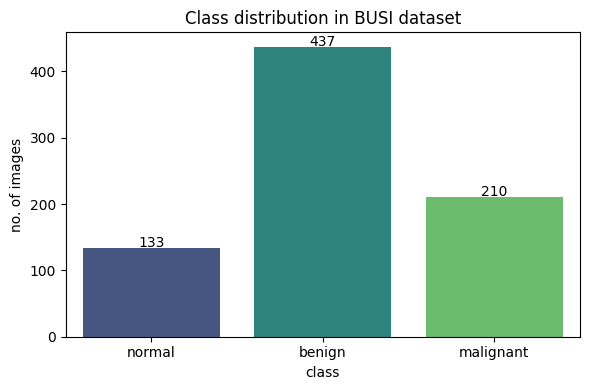

In [ ]:
counts = []
for i in range(len(class_names)):
    counts.append(labels.count(i))

plt.figure(figsize=(6, 4))
sns.barplot(x=class_names, y=counts, palette="viridis")
plt.title("Class distribution in BUSI dataset")
plt.xlabel("class")
plt.ylabel("no. of images")

for i in range(len(counts)):
    plt.text(i, counts[i] + 2, str(counts[i]), ha='center')

plt.tight_layout()
plt.savefig('/content/class_distribution.png', dpi=150)
plt.show()

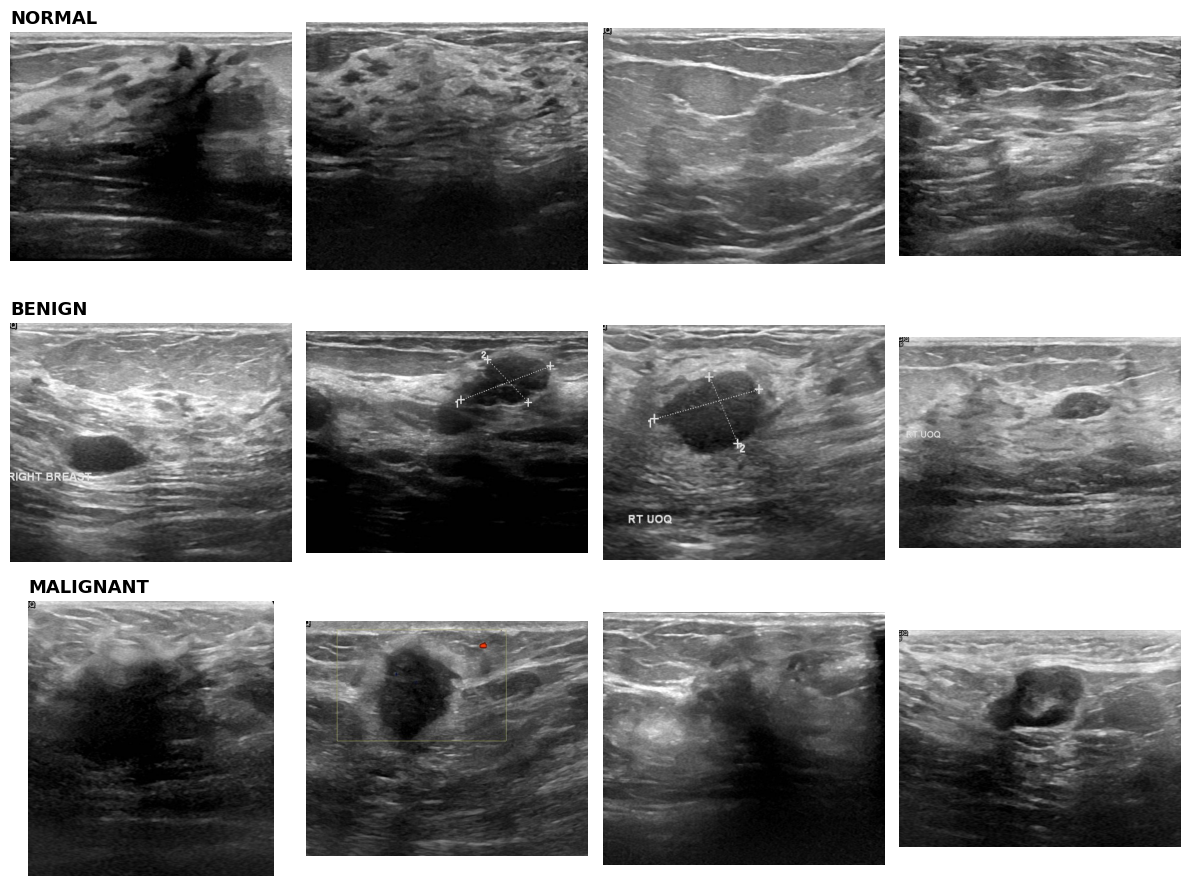

In [ ]:
samples_per_class = 4

fig, axes = plt.subplots(len(class_names), samples_per_class, figsize=(samples_per_class * 3, len(class_names) * 3))

for row in range(len(class_names)):

    cls = class_names[row]
    cls_idx = class_to_idx[cls]

    cls_paths = []
    for p, l in zip(image_paths, labels):
        if l == cls_idx:
            cls_paths.append(p)
        if len(cls_paths) == samples_per_class:
            break

    for col in range(samples_per_class):
        ax = axes[row, col]
        if col < len(cls_paths):
            img = Image.open(cls_paths[col]).convert('RGB')
            ax.imshow(img)
        ax.axis('off')

    axes[row, 0].set_title(cls.upper(), loc='left', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/sample_images.png', dpi=150)
plt.show()

In [ ]:
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths, labels, test_size=0.3, stratify=labels, random_state=42
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
)

print("train:", len(train_paths))
print("val:", len(val_paths))
print("test:", len(test_paths))

train: 546
val: 117
test: 117


In [ ]:
img_size = 224


train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


class BUSIDataset(Dataset):

    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        img = Image.open(self.paths[idx]).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            img = self.transform(img)

        return img, label


train_dataset = BUSIDataset(train_paths, train_labels, train_transform)
val_dataset = BUSIDataset(val_paths, val_labels, eval_transform)
test_dataset = BUSIDataset(test_paths, test_labels, eval_transform)

batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

In [ ]:
def build_model(num_classes=3):

    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    model.fc = nn.Linear(model.fc.in_features, num_classes)

    return model


model = build_model(num_classes=len(class_names))
model = model.to(device)

print(model.fc)

Linear(in_features=512, out_features=3, bias=True)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

In [ ]:
num_epochs = 20

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

best_val_acc = 0.0

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for imgs, lbls in train_loader:

        imgs = imgs.to(device)
        lbls = lbls.to(device)

        optimizer.zero_grad()

        outputs = model(imgs)
        loss = criterion(outputs, lbls)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0)

        _, preds = torch.max(outputs, 1)
        correct += (preds == lbls).sum().item()
        total += lbls.size(0)

    train_loss = running_loss / total
    train_acc = correct / total


    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for imgs, lbls in val_loader:

            imgs = imgs.to(device)
            lbls = lbls.to(device)

            outputs = model(imgs)
            loss = criterion(outputs, lbls)

            val_loss_total += loss.item() * imgs.size(0)

            _, preds = torch.max(outputs, 1)
            val_correct += (preds == lbls).sum().item()
            val_total += lbls.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"epoch {epoch+1}/{num_epochs}  train_loss={train_loss:.4f} train_acc={train_acc:.4f}  val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/content/best_model.pth')
        print("  new best model saved")

print("done training. best val acc:", best_val_acc)

epoch 1/20  train_loss=0.8782 train_acc=0.5824  val_loss=0.5873 val_acc=0.7179
  new best model saved
epoch 2/20  train_loss=0.4460 train_acc=0.8407  val_loss=0.4703 val_acc=0.8120
  new best model saved
epoch 3/20  train_loss=0.3398 train_acc=0.8828  val_loss=0.4613 val_acc=0.8034
epoch 4/20  train_loss=0.2363 train_acc=0.9267  val_loss=0.4655 val_acc=0.8291
  new best model saved
epoch 5/20  train_loss=0.1746 train_acc=0.9432  val_loss=0.3885 val_acc=0.8376
  new best model saved
epoch 6/20  train_loss=0.1245 train_acc=0.9597  val_loss=0.3949 val_acc=0.8462
  new best model saved
epoch 7/20  train_loss=0.1052 train_acc=0.9780  val_loss=0.3570 val_acc=0.8547
  new best model saved
epoch 8/20  train_loss=0.1156 train_acc=0.9560  val_loss=0.3699 val_acc=0.8547
epoch 9/20  train_loss=0.1049 train_acc=0.9744  val_loss=0.4178 val_acc=0.8803
  new best model saved
epoch 10/20  train_loss=0.1073 train_acc=0.9707  val_loss=0.4940 val_acc=0.8376
epoch 11/20  train_loss=0.1091 train_acc=0.9707 

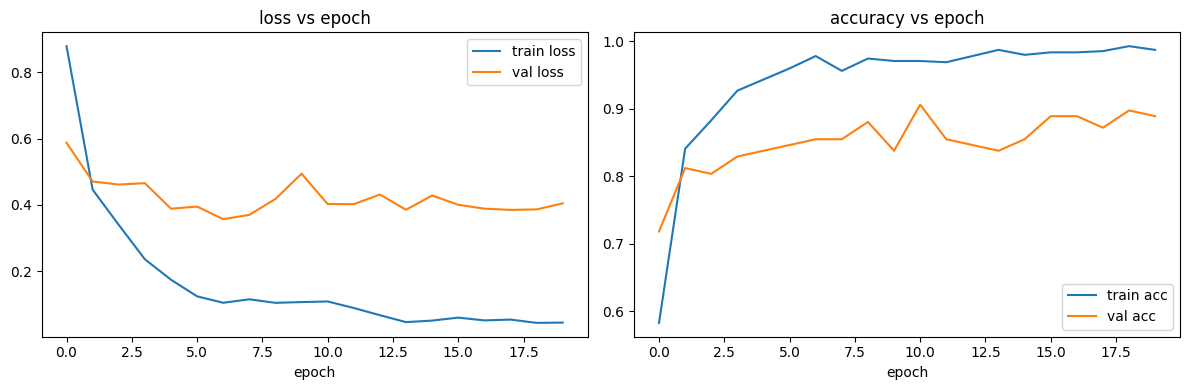

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['train_loss'], label='train loss')
axes[0].plot(history['val_loss'], label='val loss')
axes[0].set_title('loss vs epoch')
axes[0].set_xlabel('epoch')
axes[0].legend()

axes[1].plot(history['train_acc'], label='train acc')
axes[1].plot(history['val_acc'], label='val acc')
axes[1].set_title('accuracy vs epoch')
axes[1].set_xlabel('epoch')
axes[1].legend()

plt.tight_layout()
plt.savefig('/content/training_curves.png', dpi=150)
plt.show()

In [ ]:
model.load_state_dict(torch.load('/content/best_model.pth', map_location=device))
model.eval()

print("best model loaded, ready to predict")

best model loaded, ready to predict


test accuracy: 87.18%

per-class precision, recall and f1-score:

              precision    recall  f1-score   support

      normal     1.0000    0.7500    0.8571        20
      benign     0.8493    0.9394    0.8921        66
   malignant     0.8621    0.8065    0.8333        31

    accuracy                         0.8718       117
   macro avg     0.9038    0.8319    0.8609       117
weighted avg     0.8785    0.8718    0.8705       117

       class  precision  recall  f1-score  support
      normal     1.0000  0.7500    0.8571       20
      benign     0.8493  0.9394    0.8921       66
   malignant     0.8621  0.8065    0.8333       31
   macro avg     0.9038  0.8319    0.8609      117
weighted avg     0.8785  0.8718    0.8705      117


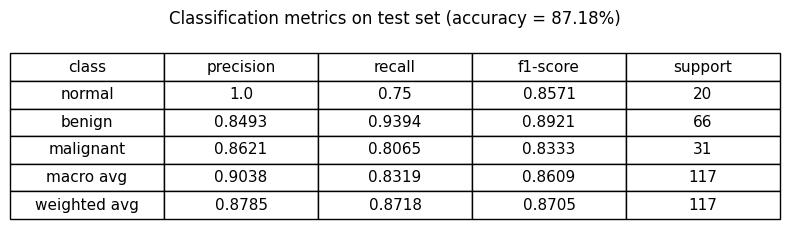

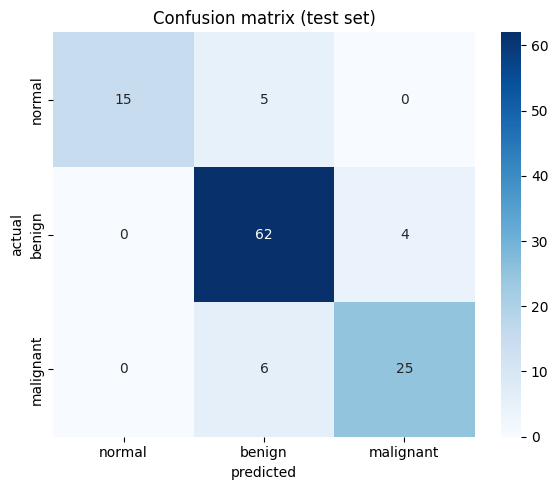

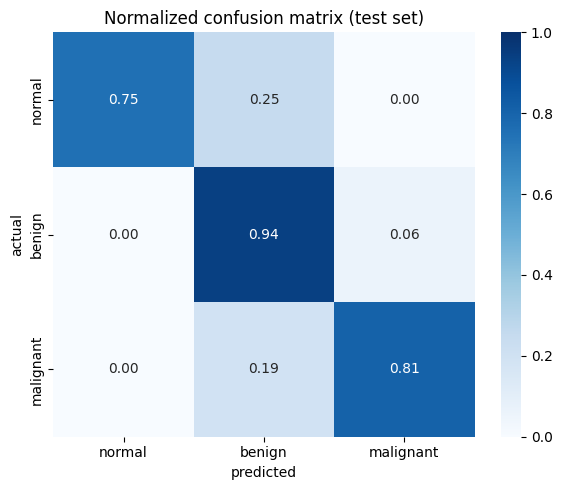

most frequent misclassifications:
  actual normal -> predicted benign: 5
  actual benign -> predicted malignant: 4
  actual malignant -> predicted benign: 6


In [ ]:
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score,
                             precision_recall_fscore_support)
import pandas as pd

all_preds = []
all_true = []

model.eval()
with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_true.extend(lbls.numpy())

all_preds = np.array(all_preds)
all_true = np.array(all_true)

test_acc = accuracy_score(all_true, all_preds)
print(f"test accuracy: {test_acc*100:.2f}%\n")

print("per-class precision, recall and f1-score:\n")
print(classification_report(all_true, all_preds, target_names=class_names, digits=4))

prec, rec, f1, support = precision_recall_fscore_support(all_true, all_preds, labels=list(range(len(class_names))))

metrics_df = pd.DataFrame({
    'class': class_names,
    'precision': prec,
    'recall': rec,
    'f1-score': f1,
    'support': support
})

for avg in ['macro', 'weighted']:
    metrics_df.loc[len(metrics_df)] = [
        avg + ' avg',
        precision_score(all_true, all_preds, average=avg),
        recall_score(all_true, all_preds, average=avg),
        f1_score(all_true, all_preds, average=avg),
        int(support.sum())
    ]

metrics_df['support'] = metrics_df['support'].astype(int)
print(metrics_df.round(4).to_string(index=False))
metrics_df.round(4).to_csv('/content/classification_metrics.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.axis('off')
table = ax.table(cellText=metrics_df.round(4).values,
                 colLabels=metrics_df.columns,
                 loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.6)
plt.title(f'Classification metrics on test set (accuracy = {test_acc*100:.2f}%)', fontsize=12)
plt.tight_layout()
plt.savefig('/content/metrics_table.png', dpi=300, bbox_inches='tight')
plt.show()

cm = confusion_matrix(all_true, all_preds, labels=list(range(len(class_names))))
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion matrix (test set)')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.tight_layout()
plt.savefig('/content/confusion_matrix.png', dpi=300)
plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names)
plt.title('Normalized confusion matrix (test set)')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.tight_layout()
plt.savefig('/content/confusion_matrix_normalized.png', dpi=300)
plt.show()

print("most frequent misclassifications:")
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            print(f"  actual {class_names[i]} -> predicted {class_names[j]}: {cm[i, j]}")

In [ ]:
class GradCAM:

    def __init__(self, model, target_layer=None):

        self.model = model
        self.model.eval()

        if target_layer is None:
            target_layer = self.model.layer4[-1]

        self.target_layer = target_layer

        self.gradients = None
        self.activations = None

        self.target_layer.register_forward_hook(self.forward_hook)
        self.target_layer.register_full_backward_hook(self.backward_hook)

    def forward_hook(self, module, input, output):
        self.activations = output.detach()

    def backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor):

        self.model.zero_grad()

        output = self.model(input_tensor)

        probs = torch.softmax(output, dim=1)
        pred_idx = torch.argmax(probs, dim=1).item()

        score = output[:, pred_idx]
        score.backward()

        gradients = self.gradients[0]
        activations = self.activations[0]

        weights = gradients.mean(dim=(1, 2))

        cam = torch.zeros(activations.shape[1:], dtype=torch.float32).to(input_tensor.device)

        for i, w in enumerate(weights):
            cam += w * activations[i]

        cam = torch.relu(cam)
        cam = cam.cpu().numpy()

        cam = cv2.resize(cam, (input_tensor.shape[3], input_tensor.shape[2]))

        cam = cam - np.min(cam)
        if np.max(cam) != 0:
            cam = cam / np.max(cam)

        return cam, pred_idx, probs.squeeze().detach().cpu().numpy()


gradcam = GradCAM(model)

In [ ]:

import torch.nn.functional as F

def predict_with_uncertainty(model, input_tensor, n_passes=20):

    model.eval()
    all_probs = []

    with torch.no_grad():
        for i in range(n_passes):

            aug_img = input_tensor.clone()


            if torch.rand(1).item() > 0.5:
                aug_img = torch.flip(aug_img, dims=[3])


            angle_deg = (torch.rand(1).item() - 0.5) * 20
            angle_rad = torch.deg2rad(torch.tensor(angle_deg))

            theta = torch.tensor([
                [torch.cos(angle_rad), -torch.sin(angle_rad), 0],
                [torch.sin(angle_rad),  torch.cos(angle_rad), 0]
            ], dtype=torch.float).unsqueeze(0).to(aug_img.device)

            grid = F.affine_grid(theta, aug_img.size(), align_corners=False)
            aug_img = F.grid_sample(aug_img, grid, align_corners=False)

            out = model(aug_img)
            p = torch.softmax(out, dim=1)
            all_probs.append(p.cpu().numpy())

    all_probs = np.array(all_probs)
    mean_probs = all_probs.mean(axis=0)[0]
    std_probs = all_probs.std(axis=0)[0]

    pred_idx = int(mean_probs.argmax())

    return pred_idx, mean_probs, std_probs

In [ ]:
confidence_threshold = 0.80
uncertainty_threshold = 0.10

birads_map = {
    'normal': 'BI-RADS 1 (Negative)',
    'benign': 'BI-RADS 3 (Probably Benign)',
    'malignant': 'BI-RADS 5 (Highly Suggestive of Malignancy)'
}

recommendation_map = {
    'normal': "No suspicious findings detected. Routine screening as per standard guidelines is recommended.",
    'benign': "Findings look benign. Routine follow up with your physician is recommended.",
    'malignant': "Findings are highly suggestive of malignancy. Please consult a radiologist or oncologist immediately for further workup."
}

low_conf_msg = "Confidence is below 80%, so this prediction should not be trusted. Please get it checked manually by a radiologist."
unstable_msg = "The model's prediction is unstable across repeated checks (high uncertainty), even though confidence looks fine. This should be manually verified by a radiologist."


def get_birads(cls_name):
    return birads_map.get(cls_name, 'unassigned')


def get_recommendation(cls_name, confidence, uncertainty=None):

    if confidence < confidence_threshold:
        return low_conf_msg


    if uncertainty is not None and uncertainty > uncertainty_threshold:
        return unstable_msg

    return recommendation_map.get(cls_name, 'no recommendation available')

In [ ]:
def predict_and_explain(image_path, ground_truth_label=None):

    img = Image.open(image_path).convert('RGB')

    input_tensor = eval_transform(img).unsqueeze(0).to(device)
    input_tensor.requires_grad_(True)


    cam, pred_idx_single, probs_single = gradcam.generate(input_tensor)


    pred_idx, mean_probs, std_probs = predict_with_uncertainty(model, input_tensor, n_passes=20)

    pred_class = class_names[pred_idx]
    confidence = float(mean_probs[pred_idx])
    uncertainty = float(std_probs[pred_idx])

    orig_np = np.array(img.resize((img_size, img_size))) / 255.0

    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0

    overlay = (0.5 * orig_np) + (0.5 * heatmap)
    overlay = np.clip(overlay, 0, 1)

    is_confident = (confidence >= confidence_threshold) and (uncertainty <= uncertainty_threshold)

    result = {
        'image_path': image_path,
        'original': orig_np,
        'heatmap': heatmap,
        'overlay': overlay,
        'prediction': pred_class,
        'confidence': confidence,
        'uncertainty': uncertainty,
        'all_probs': {class_names[i]: float(mean_probs[i]) for i in range(len(class_names))},
        'birads': get_birads(pred_class),
        'recommendation': get_recommendation(pred_class, confidence, uncertainty),
        'ground_truth': ground_truth_label,
        'is_confident': is_confident,
        'flag': 'confident prediction' if is_confident else 'low confidence / high uncertainty - needs review'
    }

    return result

In [ ]:
def show_result_page(result):

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(result['original'])
    axes[0].set_title('original image')
    axes[0].axis('off')

    axes[1].imshow(result['heatmap'])
    axes[1].set_title('grad-cam heatmap')
    axes[1].axis('off')

    axes[2].imshow(result['overlay'])
    axes[2].set_title('overlay')
    axes[2].axis('off')

    gt_text = result['ground_truth'] if result['ground_truth'] else 'unknown'

    fig.suptitle(
        f"ground truth: {gt_text}   |   ai prediction: {result['prediction'].upper()}   |   "
        f"confidence: {result['confidence']*100:.1f}%   |   {result['flag']}",
        fontsize=11
    )

    plt.tight_layout()
    plt.savefig('/content/result_page.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("class probabilities (averaged over TTA passes):")
    for cls, p in result['all_probs'].items():
        print(f"  {cls}: {p*100:.2f}%")

    print()
    print(f"confidence      : {result['confidence']*100:.2f}%")
    print(f"uncertainty     : +/- {result['uncertainty']*100:.2f}%   (lower = more stable prediction)")

    print()
    print("ai estimated bi-rads :", result['birads'])

    print()
    print("ai recommendation:", result['recommendation'])

Saving Screenshot 2026-11-05 130632.png to Screenshot 2026-11-05 130632 (1).png
enter the true label for this image (normal/benign/malignant): malignant


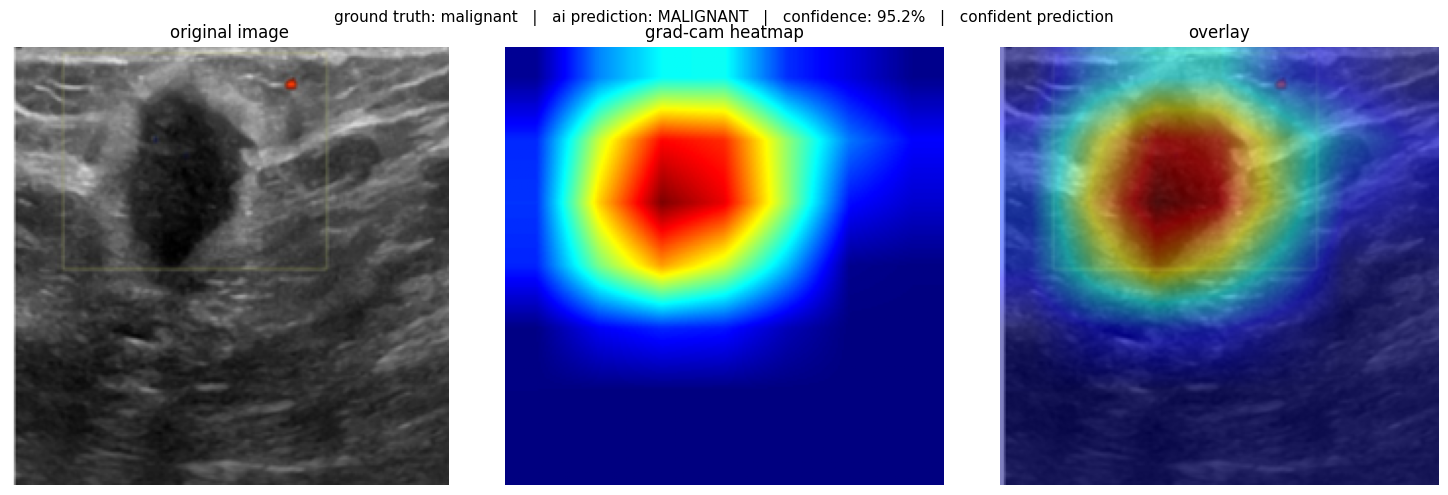

class probabilities (averaged over TTA passes):
  normal: 0.29%
  benign: 4.52%
  malignant: 95.19%

confidence      : 95.19%
uncertainty     : +/- 5.01%   (lower = more stable prediction)

ai estimated bi-rads : BI-RADS 5 (Highly Suggestive of Malignancy)

ai recommendation: Findings are highly suggestive of malignancy. Please consult a radiologist or oncologist immediately for further workup.


In [ ]:
from google.colab import files

uploaded = files.upload()
uploaded_filename = list(uploaded.keys())[0]
uploaded_path = '/content/' + uploaded_filename


ground_truth = input("enter the true label for this image (normal/benign/malignant): ").strip().lower()

if ground_truth not in class_names:
    print("that's not a valid class, setting ground truth as unknown")
    ground_truth = None

result = predict_and_explain(uploaded_path, ground_truth_label=ground_truth)
show_result_page(result)